In [1]:
# Import TensorFlow
import tensorflow as tf

# Import NumPy
import numpy as np

# Import Pandas
import pandas as pd

# Import OS
import os

# Import Scikit-learn utilities
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# Import plotting libraries
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

print("TensorFlow version:", tf.__version__)

print("GPU devices:", tf.config.list_physical_devices("GPU"))

All libraries imported successfully!
TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("\nFolder:", root)

    for file in files[:10]:
        print("  File:", file)


Folder: /kaggle/input

Folder: /kaggle/input/competitions

Folder: /kaggle/input/competitions/aptos2019-blindness-detection
  File: sample_submission.csv
  File: train.csv
  File: test.csv

Folder: /kaggle/input/competitions/aptos2019-blindness-detection/train_images
  File: ef476be214d4.png
  File: 6dcde47060f9.png
  File: ec363f48867b.png
  File: 17f6c7072f61.png
  File: b49b2fac2514.png
  File: af6166d57f13.png
  File: 8d13c46e7d75.png
  File: c3b15bf9b4bc.png
  File: be68322c7223.png
  File: 88e4399d207c.png

Folder: /kaggle/input/competitions/aptos2019-blindness-detection/test_images
  File: 755615db51d3.png
  File: d8f6c660bf2d.png
  File: 619ce2c77917.png
  File: 94a6e4f3c625.png
  File: ee506d853270.png
  File: acd52452b9a2.png
  File: b0b0d564e6c6.png
  File: 228769e96741.png
  File: a87e705d63ee.png
  File: 8c49d9de02d6.png

Folder: /kaggle/input/models

Folder: /kaggle/input/models/hemasakshis

Folder: /kaggle/input/models/hemasakshis/dr-initial-model

Folder: /kaggle/input

In [3]:
# Dataset directory
DATA_DIR = "/kaggle/input/competitions/aptos2019-blindness-detection"

# CSV file containing training labels
CSV_PATH = os.path.join(DATA_DIR, "train.csv")

# Folder containing retinal images
IMAGE_DIR = os.path.join(DATA_DIR, "train_images")

# Previously trained ResNet50 model
MODEL_PATH = "/kaggle/input/models/hemasakshis/dr-initial-model/tensorflow2/default/1/best_resnet50.keras"

# Check whether all paths exist
print("CSV exists:", os.path.exists(CSV_PATH))
print("Image folder exists:", os.path.exists(IMAGE_DIR))
print("Model exists:", os.path.exists(MODEL_PATH))

CSV exists: True
Image folder exists: True
Model exists: True


In [4]:
# Load the CSV file
df = pd.read_csv(CSV_PATH)

# Display the first five rows
print("First five rows:")
display(df.head())

# Display dataset information
print("\nDataset shape:", df.shape)

# Display column names
print("\nColumn names:", df.columns.tolist())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

First five rows:


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0



Dataset shape: (3662, 2)

Column names: ['id_code', 'diagnosis']

Missing values:
id_code      0
diagnosis    0
dtype: int64


In [5]:
# Create complete image paths
df["image_path"] = df["id_code"].apply(
    lambda x: os.path.join(IMAGE_DIR, x + ".png")
)

# Extract image paths
image_paths = df["image_path"].values

# Extract diagnosis labels
labels = df["diagnosis"].values

print("Total images:", len(image_paths))
print("Total labels:", len(labels))

print("\nFirst 5 image paths:")
print(image_paths[:5])

print("\nFirst 5 labels:")
print(labels[:5])

# Check whether all image files exist
print("\nAll images exist:", all(os.path.exists(p) for p in image_paths))

Total images: 3662
Total labels: 3662

First 5 image paths:
['/kaggle/input/competitions/aptos2019-blindness-detection/train_images/000c1434d8d7.png'
 '/kaggle/input/competitions/aptos2019-blindness-detection/train_images/001639a390f0.png'
 '/kaggle/input/competitions/aptos2019-blindness-detection/train_images/0024cdab0c1e.png'
 '/kaggle/input/competitions/aptos2019-blindness-detection/train_images/002c21358ce6.png'
 '/kaggle/input/competitions/aptos2019-blindness-detection/train_images/005b95c28852.png']

First 5 labels:
[2 4 1 0 0]

All images exist: True


In [7]:
# First split: 70% training and 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: Divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 2563
Validation images: 549
Testing images: 550


In [8]:
# Import image preprocessing tools
from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.applications.resnet50 import preprocess_input

# Define image size
IMG_SIZE = 224

# Function to load and preprocess an image
def preprocess_image(image_path):

    # Load image and resize it
    img = load_img(
        image_path,
        target_size=(IMG_SIZE, IMG_SIZE)
    )

    # Convert image into NumPy array
    img = img_to_array(img)

    # Apply ResNet50 preprocessing
    img = preprocess_input(img)

    return img

print("Image preprocessing function created successfully!")

Image preprocessing function created successfully!


In [13]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32

# Function to load an image and its label
def load_and_preprocess_image(image_path, label):

    # Read image file
    image = tf.io.read_file(image_path)

    # Decode PNG image into RGB format
    image = tf.image.decode_png(image, channels=3)

    # Resize image to 224 x 224
    image = tf.image.resize(image, [224, 224])

    # Apply ResNet50 preprocessing
    image = tf.keras.applications.resnet50.preprocess_input(image)

    # Convert label to integer format
    label = tf.cast(label, tf.int32)

    return image, label


# Create training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_dataset = train_dataset.shuffle(
    buffer_size=len(X_train),
    seed=42
)

train_dataset = train_dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=AUTOTUNE
)

train_dataset = train_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


# Create validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

val_dataset = val_dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=AUTOTUNE
)

val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


# Create testing dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_dataset = test_dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=AUTOTUNE
)

test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


print("Training, validation and testing datasets created!")

Training, validation and testing datasets created!


In [14]:
for images, labels_batch in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels_batch.shape)
    print("Image data type:", images.dtype)
    print("Label data type:", labels_batch.dtype)
    print("Pixel value range:",
          tf.reduce_min(images).numpy(),
          "to",
          tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int32'>
Pixel value range: -123.68 to 150.94415


In [15]:
# Load the previously trained model
model = tf.keras.models.load_model(MODEL_PATH)

print("Trained model loaded successfully!")

# Display model summary
model.summary()

Trained model loaded successfully!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,618,449 (90.10 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 20,492 (80.05 KB)

In [16]:
# Get the unique classes
classes = np.unique(y_train)

# Calculate class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

# Convert weights into a dictionary
class_weights = dict(zip(classes, weights))

print("Class weights:")
print(class_weights)


Class weights:
{np.int64(0): np.float64(0.4058590657165479), np.int64(1): np.float64(1.9791505791505792), np.int64(2): np.float64(0.7333333333333333), np.int64(3): np.float64(3.797037037037037), np.int64(4): np.float64(2.476328502415459)}


In [17]:
# Access the ResNet50 base model
base_model = model.get_layer("resnet50")

# Allow fine-tuning
base_model.trainable = True

# Freeze the first 140 layers
for layer in base_model.layers[:140]:
    layer.trainable = False

# Count trainable and frozen layers
trainable_layers = sum(
    layer.trainable for layer in base_model.layers
)

frozen_layers = sum(
    not layer.trainable for layer in base_model.layers
)

print("Total ResNet50 layers:", len(base_model.layers))
print("Trainable layers:", trainable_layers)
print("Frozen layers:", frozen_layers)

Total ResNet50 layers: 175
Trainable layers: 35
Frozen layers: 140


In [18]:
# Recompile with a smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled successfully!")

Model recompiled successfully!


In [19]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10)
])

print("Image augmentation layer created successfully!")

Image augmentation layer created successfully!


In [20]:
augmented_train_dataset = train_dataset.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    ),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

In [21]:
model_C = tf.keras.models.load_model(MODEL_PATH)

print("Original baseline model loaded for Experiment C!")

Original baseline model loaded for Experiment C!


In [22]:
base_model_C = model_C.get_layer("resnet50")

base_model_C.trainable = True

for layer in base_model_C.layers[:140]:
    layer.trainable = False

print("Total ResNet50 layers:", len(base_model_C.layers))
print("Trainable layers:",
      sum(layer.trainable for layer in base_model_C.layers))
print("Frozen layers:",
      sum(not layer.trainable for layer in base_model_C.layers))

Total ResNet50 layers: 175
Trainable layers: 35
Frozen layers: 140


In [23]:
checkpoint_C = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/finetuned_augmentation.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stopping_C = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

print("Experiment C callbacks created successfully!")

Experiment C callbacks created successfully!


In [24]:
model_C.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Experiment C recompiled successfully!")

Experiment C recompiled successfully!


In [25]:
history_C = model_C.fit(
    augmented_train_dataset,
    validation_data=val_dataset,
    epochs=10,
    class_weight=class_weights,
    callbacks=[
        checkpoint_C,
        early_stopping_C
    ]
)

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5684 - loss: 1.8505
Epoch 1: val_loss improved from None to 0.92936, saving model to /kaggle/working/finetuned_augmentation.keras

Epoch 1: finished saving model to /kaggle/working/finetuned_augmentation.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - accuracy: 0.6141 - loss: 1.5863 - val_accuracy: 0.6594 - val_loss: 0.9294
Epoch 2/10
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 972ms/step - accuracy: 0.6587 - loss: 1.1229
Epoch 2: val_loss improved from 0.92936 to 0.89204, saving model to /kaggle/working/finetuned_augmentation.keras

Epoch 2: finished saving model to /kaggle/working/finetuned_augmentation.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 95s 1s/step - accuracy: 0.6750 - loss: 1.0621 - val_accuracy: 0.6685 - val_loss: 0.8920
Epoch 3/10
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 964ms/step - accuracy: 0.7245 - loss: 0.8613
Epoch 3: val_loss improved from 0.89204 to 0.83546, saving model to /kaggle/working/finetuned_augmentation.keras

Epoch 3: finished

In [26]:
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score
import numpy as np

# Load the best saved Experiment C model
model_C = tf.keras.models.load_model(
    "/kaggle/working/finetuned_augmentation.keras"
)

# Generate predictions on validation data
y_true = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

y_prob = model_C.predict(val_dataset)
y_pred = np.argmax(y_prob, axis=1)

# Class names
class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

# Classification report
print("EXPERIMENT C - CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

# Confusion matrix
print("CONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred))

# Quadratic Weighted Kappa
qwk = cohen_kappa_score(
    y_true,
    y_pred,
    weights="quadratic"
)

print("QWK Score:", qwk)

18/18 ━━━━━━━━━━━━━━━━━━━━ 21s 872ms/step
EXPERIMENT C - CLASSIFICATION REPORT
                  precision    recall  f1-score   support

           No DR       0.96      0.95      0.95       271
            Mild       0.46      0.56      0.50        55
        Moderate       0.73      0.63      0.68       150
          Severe       0.37      0.66      0.47        29
Proliferative DR       0.62      0.41      0.49        44

        accuracy                           0.77       549
       macro avg       0.62      0.64      0.62       549
    weighted avg       0.78      0.77      0.77       549

CONFUSION MATRIX
[[257   7   6   0   1]
 [  8  31  15   0   1]
 [  4  22  95  23   6]
 [  0   2   5  19   3]
 [  0   6  10  10  18]]
QWK Score: 0.84122348225633


In [27]:
print("Experiment C loaded:", "model_C" in globals())
print("Validation dataset loaded:", "val_dataset" in globals())
print("Test dataset loaded:", "test_dataset" in globals())

Experiment C loaded: True
Validation dataset loaded: True
Test dataset loaded: True


In [28]:
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score
import numpy as np

# Actual labels from test dataset
y_test_true = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

# Predictions from Experiment C
y_test_prob = model_C.predict(test_dataset)
y_test_pred = np.argmax(y_test_prob, axis=1)

# Class names
class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

# Classification report
print("EXPERIMENT C - FINAL TEST RESULTS")
print(classification_report(
    y_test_true,
    y_test_pred,
    target_names=class_names
))

# Confusion matrix
print("CONFUSION MATRIX")
print(confusion_matrix(y_test_true, y_test_pred))

# QWK
test_qwk = cohen_kappa_score(
    y_test_true,
    y_test_pred,
    weights="quadratic"
)

print("Test QWK:", test_qwk)

18/18 ━━━━━━━━━━━━━━━━━━━━ 18s 981ms/step
EXPERIMENT C - FINAL TEST RESULTS
                  precision    recall  f1-score   support

           No DR       0.97      0.97      0.97       271
            Mild       0.50      0.46      0.48        56
        Moderate       0.71      0.63      0.67       150
          Severe       0.27      0.52      0.36        29
Proliferative DR       0.50      0.45      0.48        44

        accuracy                           0.76       550
       macro avg       0.59      0.61      0.59       550
    weighted avg       0.78      0.76      0.76       550

CONFUSION MATRIX
[[262   6   3   0   0]
 [  5  26  20   4   1]
 [  4  16  94  24  12]
 [  0   1   6  15   7]
 [  0   3   9  12  20]]
Test QWK: 0.8605511494926251


In [29]:
model_C.save("/kaggle/working/final_dr_model.keras")

print("Experiment C saved successfully!")

Experiment C saved successfully!


In [30]:
import numpy as np

# Get training labels
if "y_train" in globals():
    training_labels = np.asarray(y_train)
else:
    training_labels = np.concatenate([
        labels.numpy() for images, labels in train_dataset
    ])

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print("TRAINING DATASET CLASS DISTRIBUTION\n")

for i, name in enumerate(class_names):
    count = np.sum(training_labels == i)
    percentage = (count / len(training_labels)) * 100

    print(f"{name}: {count} images ({percentage:.2f}%)")

TRAINING DATASET CLASS DISTRIBUTION

No DR: 1263 images (49.28%)
Mild: 259 images (10.11%)
Moderate: 699 images (27.27%)
Severe: 135 images (5.27%)
Proliferative DR: 207 images (8.08%)


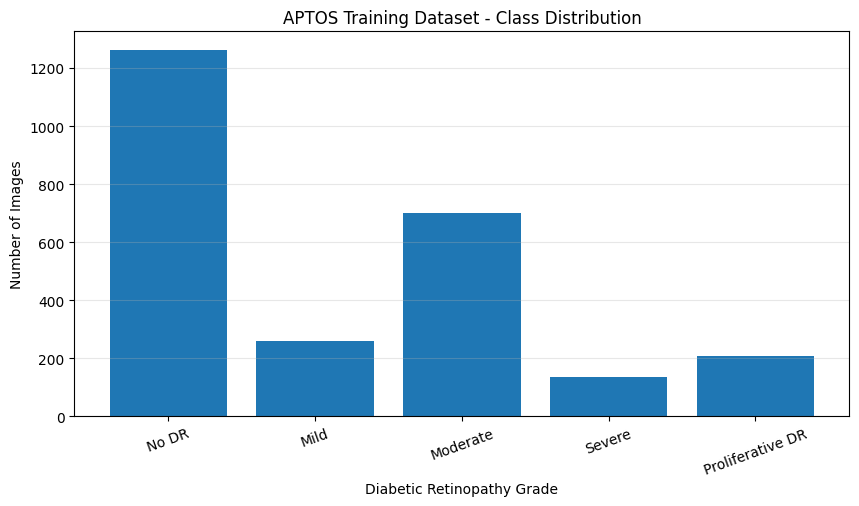

In [31]:
import matplotlib.pyplot as plt
import numpy as np

unique_classes, counts = np.unique(
    training_labels,
    return_counts=True
)

plt.figure(figsize=(10, 5))
plt.bar(class_names, counts)

plt.title("APTOS Training Dataset - Class Distribution")
plt.xlabel("Diabetic Retinopathy Grade")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [32]:
print("Existing class weights:")
print(class_weights)

Existing class weights:
{np.int64(0): np.float64(0.4058590657165479), np.int64(1): np.float64(1.9791505791505792), np.int64(2): np.float64(0.7333333333333333), np.int64(3): np.float64(3.797037037037037), np.int64(4): np.float64(2.476328502415459)}


In [33]:
import numpy as np

# Actual validation labels
y_val_true = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

# Experiment C predictions
y_val_prob = model_C.predict(val_dataset)
y_val_pred = np.argmax(y_val_prob, axis=1)

print("ACTUAL vs PREDICTED VALIDATION DISTRIBUTION\n")

for i, name in enumerate(class_names):

    actual_count = np.sum(y_val_true == i)
    predicted_count = np.sum(y_val_pred == i)

    print(f"{name}")
    print("Actual images:   ", actual_count)
    print("Predicted images:", predicted_count)
    print()

18/18 ━━━━━━━━━━━━━━━━━━━━ 16s 853ms/step
ACTUAL vs PREDICTED VALIDATION DISTRIBUTION

No DR
Actual images:    271
Predicted images: 269

Mild
Actual images:    55
Predicted images: 68

Moderate
Actual images:    150
Predicted images: 131

Severe
Actual images:    29
Predicted images: 52

Proliferative DR
Actual images:    44
Predicted images: 29



In [34]:
import numpy as np

print("AVERAGE PREDICTED PROBABILITIES\n")

for i, name in enumerate(class_names):

    class_mask = (y_val_true == i)

    average_probs = np.mean(
        y_val_prob[class_mask],
        axis=0
    )

    print(f"\nActual class: {name}")

    for j, predicted_name in enumerate(class_names):
        print(
            f"{predicted_name}: "
            f"{average_probs[j]:.4f}"
        )

AVERAGE PREDICTED PROBABILITIES


Actual class: No DR
No DR: 0.9052
Mild: 0.0434
Moderate: 0.0392
Severe: 0.0050
Proliferative DR: 0.0072

Actual class: Mild
No DR: 0.1533
Mild: 0.4939
Moderate: 0.2425
Severe: 0.0550
Proliferative DR: 0.0552

Actual class: Moderate
No DR: 0.0404
Mild: 0.1451
Moderate: 0.5063
Severe: 0.2049
Proliferative DR: 0.1032

Actual class: Severe
No DR: 0.0071
Mild: 0.0374
Moderate: 0.2568
Severe: 0.5635
Proliferative DR: 0.1352

Actual class: Proliferative DR
No DR: 0.0075
Mild: 0.1516
Moderate: 0.2625
Severe: 0.2448
Proliferative DR: 0.3336


In [35]:

import os

file_path = "/kaggle/working/finetuned_augmentation.keras"

if os.path.exists(file_path):
    print("Model file found!")
    print("File size:", round(os.path.getsize(file_path) / (1024**2), 2), "MB")
else:
    print("Model file not found at this location.")


Model file found!
File size: 205.02 MB


In [37]:

def load_and_preprocess_image_D(image_path, label):

    # Read image
    image = tf.io.read_file(image_path)

    # Decode PNG into RGB
    image = tf.image.decode_png(image, channels=3)

    # Resize to 224 x 224
    image = tf.image.resize(image, [224, 224])

    # Convert label to integer
    label = tf.cast(label, tf.int32)

    return image, label

print("Experiment D image loading function created successfully!")


Experiment D image loading function created successfully!


In [38]:

# Step 1: Create a fresh training dataset
train_dataset_D = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

# Step 2: Load and resize images without ResNet50 preprocessing
train_dataset_D = train_dataset_D.map(
    load_and_preprocess_image_D,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Step 3: Shuffle and batch
train_dataset_D = train_dataset_D.shuffle(
    buffer_size=len(X_train),
    seed=42
).batch(32)

# Step 4: Apply augmentation first, then ResNet50 preprocessing
def augment_and_preprocess_D(images, labels):
    images = data_augmentation(images, training=True)

    images = tf.keras.applications.resnet50.preprocess_input(
        images
    )

    return images, labels

# Step 5: Complete the pipeline
train_dataset_D = train_dataset_D.map(
    augment_and_preprocess_D,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

print("Experiment D training dataset is ready!")


Experiment D training dataset is ready!


In [39]:

for images, labels in train_dataset_D.take(1):
    print("Image batch shape:", images.shape)
    print("Image data type:", images.dtype)
    print("Pixel value range:",
          tf.reduce_min(images).numpy(),
          "to",
          tf.reduce_max(images).numpy())
    print("Labels shape:", labels.shape)


Image batch shape: (32, 224, 224, 3)
Image data type: <dtype: 'float32'>
Pixel value range: -123.68 to 150.23007
Labels shape: (32,)


In [40]:
# Load the original baseline model
model_D = tf.keras.models.load_model(MODEL_PATH)

print("Original ResNet50 model loaded successfully!")

print("Input shape:", model_D.input_shape)
print("Output shape:", model_D.output_shape)

Original ResNet50 model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)


In [41]:

# Access the ResNet50 base model
base_model_D = model_D.get_layer("resnet50")

# Allow fine-tuning
base_model_D.trainable = True

# Freeze the first 115 layers
for layer in base_model_D.layers[:115]:
    layer.trainable = False

# Count trainable and frozen layers
trainable_layers = sum(
    layer.trainable for layer in base_model_D.layers
)

frozen_layers = sum(
    not layer.trainable for layer in base_model_D.layers
)

print("Total ResNet50 layers:", len(base_model_D.layers))
print("Trainable layers:", trainable_layers)
print("Frozen layers:", frozen_layers)


Total ResNet50 layers: 175
Trainable layers: 60
Frozen layers: 115


In [42]:

model_D.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Experiment D model compiled successfully!")


Experiment D model compiled successfully!


In [43]:

# Early stopping
early_stopping_D = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Save the best model
checkpoint_D = tf.keras.callbacks.ModelCheckpoint(
    filepath="/kaggle/working/finetuned_D_60_layers.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

print("Experiment D callbacks configured successfully!")


Experiment D callbacks configured successfully!


In [44]:

class_weights_D = {
    0: 0.4058590657165479,  # No DR
    1: 1.9791505791505792,  # Mild
    2: 0.7333333333333333,  # Moderate
    3: 3.797037037037037,   # Severe
    4: 2.476328502415459    # Proliferative DR
}

print("Experiment D class weights:")
for class_id, weight in class_weights_D.items():
    print(class_id, ":", weight)


Experiment D class weights:
0 : 0.4058590657165479
1 : 1.9791505791505792
2 : 0.7333333333333333
3 : 3.797037037037037
4 : 2.476328502415459


In [45]:

history_D = model_D.fit(
    train_dataset_D,
    validation_data=val_dataset,
    epochs=15,
    class_weight=class_weights_D,
    callbacks=[
        early_stopping_D,
        checkpoint_D
    ],
    verbose=1
)


Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - accuracy: 0.5662 - loss: 1.9250
Epoch 1: val_loss improved from None to 0.92473, saving model to /kaggle/working/finetuned_D_60_layers.keras

Epoch 1: finished saving model to /kaggle/working/finetuned_D_60_layers.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 146s 555ms/step - accuracy: 0.6036 - loss: 1.6263 - val_accuracy: 0.6667 - val_loss: 0.9247
Epoch 2/15
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.6864 - loss: 1.0418
Epoch 2: val_loss improved from 0.92473 to 0.82920, saving model to /kaggle/working/finetuned_D_60_layers.keras

Epoch 2: finished saving model to /kaggle/working/finetuned_D_60_layers.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 108s 364ms/step - accuracy: 0.6976 - loss: 1.0164 - val_accuracy: 0.6922 - val_loss: 0.8292
Epoch 3/15
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.7346 - loss: 0.8401
Epoch 3: val_loss improved from 0.82920 to 0.80788, saving model to /kaggle/working/finetuned_D_60_layers.keras

Epoch 3: fin

In [46]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    cohen_kappa_score
)
import numpy as np

# Predict validation images
y_pred_prob_D = model_D.predict(val_dataset)

# Convert probabilities into predicted classes
y_pred_D = np.argmax(y_pred_prob_D, axis=1)

# Actual validation labels
y_true_D = np.array(y_val)

# Classification report
print("EXPERIMENT D - VALIDATION CLASSIFICATION REPORT")
print(classification_report(
    y_true_D,
    y_pred_D,
    target_names=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative DR"
    ]
))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_true_D, y_pred_D))

# Quadratic Weighted Kappa
qwk_D = cohen_kappa_score(
    y_true_D,
    y_pred_D,
    weights="quadratic"
)

print("QWK:", qwk_D)


18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 886ms/step
EXPERIMENT D - VALIDATION CLASSIFICATION REPORT
                  precision    recall  f1-score   support

           No DR       0.95      0.96      0.95       271
            Mild       0.47      0.49      0.48        55
        Moderate       0.71      0.69      0.70       150
          Severe       0.40      0.59      0.47        29
Proliferative DR       0.67      0.45      0.54        44

        accuracy                           0.78       549
       macro avg       0.64      0.64      0.63       549
    weighted avg       0.78      0.78      0.78       549

Confusion Matrix:
[[260   5   6   0   0]
 [  9  27  17   0   2]
 [  5  20 103  17   5]
 [  0   1   8  17   3]
 [  0   4  11   9  20]]
QWK: 0.8574783835162814


In [47]:
model_D.save("/kaggle/working/final_experiment_D.keras")
print("Experiment D model saved successfully!")

Experiment D model saved successfully!
